Question 64. Create a bipartite graph with OID as one set and Category as the other.

Original dataset:


,OID,Date,City,Region,Age,Category,Sales,Profit,Latitude,Longitude
0,O01,2026-01-01,Delhi,North,25,Grocery,1500,200,28.61,77.23
1,O02,2026-01-03,Mumbai,West,32,Electronics,12000,1500,19.07,72.87
2,O03,2026-01-05,Chennai,South,28,Clothing,3500,500,13.08,80.27
3,O04,2026-01-07,Kolkata,East,40,Grocery,2000,250,22.57,88.36
4,O05,2026-01-09,Bangalore,South,35,Electronics,15000,2000,12.97,77.59
5,O06,2026-01-11,Jaipur,North,29,Clothing,4000,600,26.91,75.79
6,O07,2026-01-13,Pune,West,31,Grocery,1800,300,18.52,73.85
7,O08,2026-01-15,Hyderabad,South,27,Electronics,11000,1300,17.38,78.48
8,O09,2026-01-17,Ahmedabad,West,45,Clothing,5000,700,23.02,72.57
9,O10,2026-01-19,Lucknow,North,38,Grocery,2200,350,26.85,80.95


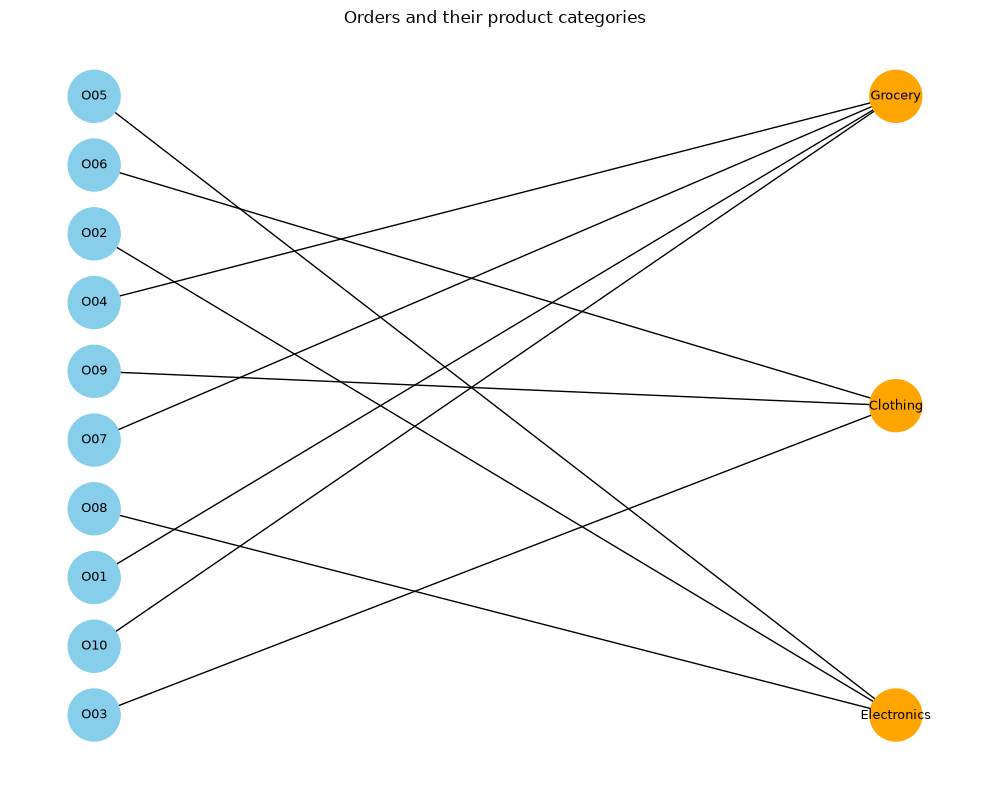

Saved question64_plot.png


In [1]:
# Step 1: Import the libraries needed for this program.
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from networkx.algorithms import bipartite

# Step 2: Load the CSV file from this question's folder into a DataFrame (table).
df = pd.read_csv("Customer_SalesData.csv")
print("Original dataset:")
display(df)

# Step 3: Create an undirected graph with separate order and category node sets.
graph = nx.Graph()
orders = df["OID"].tolist()
categories = sorted(df["Category"].unique())

# Step 4: Mark each side of the bipartite graph and connect orders to their categories.
graph.add_nodes_from(orders, bipartite=0)
graph.add_nodes_from(categories, bipartite=1)
graph.add_edges_from(df[["OID", "Category"]].itertuples(index=False, name=None))

# Step 5: Check that all edges connect the two different node sets.
assert bipartite.is_bipartite(graph)

# Step 6: Arrange the two sets on opposite sides and draw the graph.
fig, ax = plt.subplots(figsize=(10, 8))
positions = nx.bipartite_layout(graph, orders)
nx.draw_networkx(graph, positions, ax=ax, node_color=["skyblue" if node in orders else "orange" for node in graph],
                 node_size=1400, font_size=9)
ax.set_title("Orders and their product categories")
ax.axis("off")

# Step 7: Export the order-category connections.
pd.DataFrame(graph.edges(), columns=["Node1", "Node2"]).to_csv("bipartite_edges.csv", index=False)

# Final step: Arrange labels, save the chart and display it below this cell.
fig.tight_layout()
fig.savefig("question64_plot.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved question64_plot.png")
